In [1]:
import jax
import jax.numpy as jnp
from flax.training import train_state
import optax
import mujoco
from mujoco import mjx
from typing import Callable, Dict
from jaxlib.xla_extension import ArrayImpl


# from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
from sysidmjx.core import generate_loss_train_functions, get_batch
from sysidmjx.assets.single_motor.dataloader.single_joint import data_load
from jax import config

config.update("jax_debug_nans", True)
jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "high")


class PARAMS:
    SEED = jax.random.PRNGKey(2)

    class DATASET:
        PATH = "generated/test.csv"
        DT = 0.001
        motor_id = 3
        num_lags = 5

    class SIM:
        PATH = "../sysidmjx/assets/single_motor/model/single_motor.xml"
        INTEGRATOR = mujoco.mjtIntegrator.mjINT_EULER
        # INTEGRATOR = mujoco.mjtIntegrator.mjINT_RK4
        ITERATIONS = 1

    class TRAIN:
        EPOCH_NUM = 300
        # BATCH_NUM = 5*6
        BATCH_SIZE = 20000
        LEARNING_RATE = 1e-2
        TX = optax.adam(LEARNING_RATE)

    # class MODEL:
    #     NUM_HIST_LAGS = 5

# Upload data

In [2]:
dataset, df =data_load(
    data_path=PARAMS.DATASET.PATH,
    motor_id=PARAMS.DATASET.motor_id,
    num_lags=PARAMS.DATASET.num_lags,
)

# Setup model

In [3]:
mj_model = mujoco.MjModel.from_xml_path(PARAMS.SIM.PATH)
mj_model.opt.timestep = PARAMS.DATASET.DT
mj_model.opt.iterations = PARAMS.SIM.ITERATIONS
mj_model.opt.integrator = PARAMS.SIM.INTEGRATOR
mj_data = mujoco.MjData(mj_model)

mjx_model = mjx.put_model(mj_model)
mjx_data = mjx.put_data(mj_model, mj_data)
print(f"integrator:{mj_model.opt.integrator}")
print(f"timestep:{mj_model.opt.timestep}")
print(f"iterations:{mj_model.opt.iterations}")

integrator:0
timestep:0.001
iterations:1


# Identify parameters and function they use

In [4]:
# Generate random keys for initialization
keys = jax.random.split(PARAMS.SEED, num=5)

# Define initial parameters for the model (set to zeros initially)
zero_params = {
    "armature": jnp.array([0.0]),
    "frictionloss": jnp.array([0.0]),
    "damping": jnp.array([0.0]),
}

# Define parameters for model initialization, randomly sampled within specific ranges
init_params = {
    "armature": jax.random.uniform(keys[2], maxval=0.001, shape=(1,)),  # Random armature between 0 and 0.001
    "frictionloss": jax.random.uniform(keys[3], maxval=0.01, shape=(1,)),  # Random friction loss between 0 and 0.01
    "damping": jax.random.uniform(keys[4], maxval=0.01, shape=(1,)),  # Random damping between 0 and 0.01
}


@jax.jit
def change_model(params:Dict, old_model:mjx.Model):
    """
    Modify the existing model by updating its parameters (armature, friction loss, damping).
    
    Args:
        params (dict): The parameters used to modify the model (armature, frictionloss, damping).
        old_model (mjx.Model): The old model instance to be updated.
    
    Returns:
        changed_model (mjx.Model): The updated model with new parameter values.
    """
    # Create a new model by replacing certain parameters with updated ones.
    changed_model = old_model.replace(
        # If needed, actuator gains or biases can be modified here
        # actuator_gainprm=actuator_gainprm,
        # actuator_biasprm=actuator_biasprm,
        
        # Replace parameters in the model with absolute values to ensure no negative values
        dof_armature=abs(params["armature"]),
        dof_frictionloss=abs(params["frictionloss"]),
        dof_damping=abs(params["damping"]),
    )
    
    return changed_model


@jax.jit
def make_action(params:Dict, data:mjx.Data, ctrl:ArrayImpl):
    """
    Computes the control action (torque) based on the position error and velocity error.
    
    Args:
        params (Dict): The parameters used in the action calculation (e.g., friction loss).
        data (mjx.Data): The current state data of the system (position and velocity).
        ctrl (ArrayImpl): The desired control input.
    
    Returns:
        tau (ArrayImpl): The calculated torque based on proportional-derivative control law.
    """
    kp = 20  # Proportional gain
    kv = 1   # Derivative gain
    
    # Calculate the torque based on position and velocity errors
    tau = kp * (ctrl - data.qpos) - kv * data.qvel
    
    # Uncomment to apply friction-based torque adjustment
    # fric = jnp.sign(data.qvel) * abs(params["frictionloss"])
    # tau = tau - fric
    
    return tau


# Generate total loss and training step functions by passing the model, data, change_model, and action functions
total_loss, train_step = generate_loss_train_functions(
    mjx_model=mjx_model,        # The model used in training
    mjx_data=mjx_data,          # The data used during training
    change_model=change_model,  # Function to modify the model during training
    make_action=make_action,    # Function to compute actions during training
)


# Training loop

In [5]:
state = train_state.TrainState.create(
    apply_fn=None,
    params=init_params,
    tx=PARAMS.TRAIN.TX,
)

loss_hist = []
params_hist = []
indxs = jax.numpy.array(range(dataset["qpos"].shape[0]))

for epoch in range(PARAMS.TRAIN.EPOCH_NUM):
    # VALIDATE
    loss = total_loss(
        state.params,
        qpos=dataset["qpos"],
        qvel=dataset["qvel"],
        ctrl_vec=dataset["qact"],
        qpos_des=dataset["qpos_next"],
    )
    loss_hist.append(loss)
    print(f"Epoch {epoch}, Loss: {loss}")

    params_hist.append(state.params)
    # TRAIN
    batch, indxs = get_batch(dataset, PARAMS.SEED, indxs, PARAMS.TRAIN.BATCH_SIZE)
    state, grads = train_step(
        state,
        qpos=batch["qpos"],
        qvel=batch["qvel"],
        ctrl_vec=batch["qact"],
        qpos_des=batch["qpos_next"],
    )

Epoch 0, Loss: 0.0031043786354729487
Epoch 1, Loss: 0.002679582246400552
Epoch 2, Loss: 0.0026515527207955675
Epoch 3, Loss: 0.0026447170124540374
Epoch 4, Loss: 0.0026422978555308333
Epoch 5, Loss: 0.002641294686272294
Epoch 6, Loss: 0.002640856669496055
Epoch 7, Loss: 0.0026406756262898246
Epoch 8, Loss: 0.0026406189397040493
Epoch 9, Loss: 0.0026406251039926853
Epoch 10, Loss: 0.0026406621104618075
Epoch 11, Loss: 0.0026407143079903235
Epoch 12, Loss: 0.002640772195017894
Epoch 13, Loss: 0.0026408304759573484
Epoch 14, Loss: 0.0026408864593720914
Epoch 15, Loss: 0.0026409383228834567
Epoch 16, Loss: 0.0026409857335879115
Epoch 17, Loss: 0.0026410274875303874
Epoch 18, Loss: 0.002641063537848302
Epoch 19, Loss: 0.0026410943064722526
Epoch 20, Loss: 0.002641120307847112
Epoch 21, Loss: 0.002641141149211962
Epoch 22, Loss: 0.002641157261812486
Epoch 23, Loss: 0.0026411690878640087
Epoch 24, Loss: 0.0026411765240765784
Epoch 25, Loss: 0.0026411802127947444
Epoch 26, Loss: 0.002641180637

# Loss Analysis

In [6]:
baseline_loss = total_loss(
    zero_params,
    qpos=dataset["qpos"],
    qvel=dataset["qvel"],
    ctrl_vec=dataset["qact"],
    qpos_des=dataset["qpos_next"],
)
adjusted_model_loss = np.array(loss_hist)
base_line = np.ones_like(adjusted_model_loss)

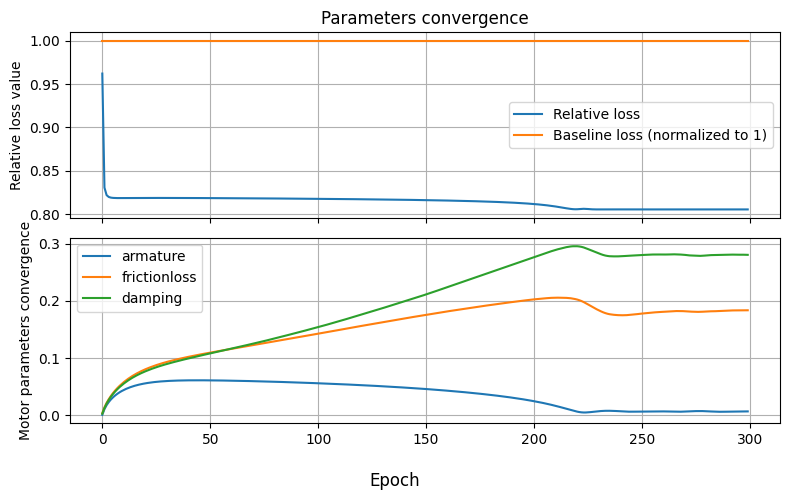

In [ ]:
import matplotlib.pyplot as plt

# Create a figure and gridspec with custom height ratios
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 5), gridspec_kw={"height_ratios": [1, 1]}, sharex=True
)
# fig, ax1 = plt.subplots(1, 1, figsize=(8, 4.5))

# # Plot on the first (larger) subplot
ax1.plot(adjusted_model_loss / baseline_loss, label="Relative loss")
ax1.plot(base_line, label="Baseline loss (normalized to 1)")
ax1.set_title("Parameters convergence")
ax1.set_ylabel("Relative loss value")
ax1.legend()
ax1.grid(True)

# Plot on the second (smaller) subplot
ax2.plot([p["armature"] for p in params_hist], label="armature")
ax2.plot([p["frictionloss"] for p in params_hist], label="frictionloss")
ax2.plot([p["damping"] for p in params_hist], label="damping")
ax2.set_ylabel("Motor parameters convergence")
ax2.legend()
ax2.grid(True)

# Set a shared x-axis label
fig.supxlabel("Epoch")
# fig.supylabel('Y-axis')

plt.tight_layout()  # Adjust spacing
plt.savefig(
    "/home/slava/projects/papers/IROC2025ActuatorNN/src/assets/loss.pdf",
    format="pdf",
    bbox_inches="tight",
)
plt.show()

In [8]:
my_best_params = params_hist[np.argmin(loss_hist)]
print(f"loss {np.min(loss_hist)}")
print("best_params", my_best_params)

loss 0.00259838835882289
best_params {'armature': Array([0.00655278], dtype=float64), 'damping': Array([0.28091444], dtype=float64), 'frictionloss': Array([0.18366513], dtype=float64)}


# GPU Simulation

In [9]:
# Modify the model using the best parameters found from training
sim_model = change_model(my_best_params, mjx_model)

# JIT compile the model step function for faster execution during simulation
jit_sim_step = jax.jit(mjx.step)

def sim_step(carry, ctrl):
    """
    Performs a single simulation step with the provided control input.
    
    Args:
        carry (object): The current state of the simulation, including positions, velocities, and other relevant data.
        ctrl (array): The control input for the simulation at this step.
    
    Returns:
        data (object): The updated state of the simulation after applying the control input.
        state (array): A concatenated array of position (qpos) and velocity (qvel) for the current step.
    """
    # Extract the current state of the simulation (carry is the state at this step)
    data = carry
    
    # Replace the control input in the state with the new control action
    data = data.tree_replace({"ctrl": make_action(my_best_params, data, ctrl)})
    
    # Apply the simulation step to the model with the new control action
    data = jit_sim_step(sim_model, data)
    
    # Return the updated data and a concatenated array of qpos and qvel
    return data, jnp.hstack([data.qpos, data.qvel])

# Initialize the simulation data with the initial position (qpos) and velocity (qvel) from the dataframe
sim_data = mjx_data.replace(
    qpos=df[["qpos"]].values[0],  # Initial position from the first entry in the dataframe
    qvel=df[["qvel"]].values[0],  # Initial velocity from the first entry in the dataframe
)

# Prepare the control history, using the "qact" column from the dataframe as the control actions
hist_ctrl = jnp.array(jnp.array(df[["qact"]].values))

# Run the simulation using the jax.lax.scan function, which iteratively applies the sim_step function
# It simulates the dynamics for the entire control history
final_data, qpos_qvel_history = jax.lax.scan(sim_step, sim_data, hist_ctrl)

# Store the results of the simulation in a dictionary for easy access
data_hist = {
    "qpos": qpos_qvel_history[:, 0],  # Extract the position history (qpos)
    "qvel": qpos_qvel_history[:, 1],  # Extract the velocity history (qvel)
    "ctrl": hist_ctrl,  # Store the control history
}


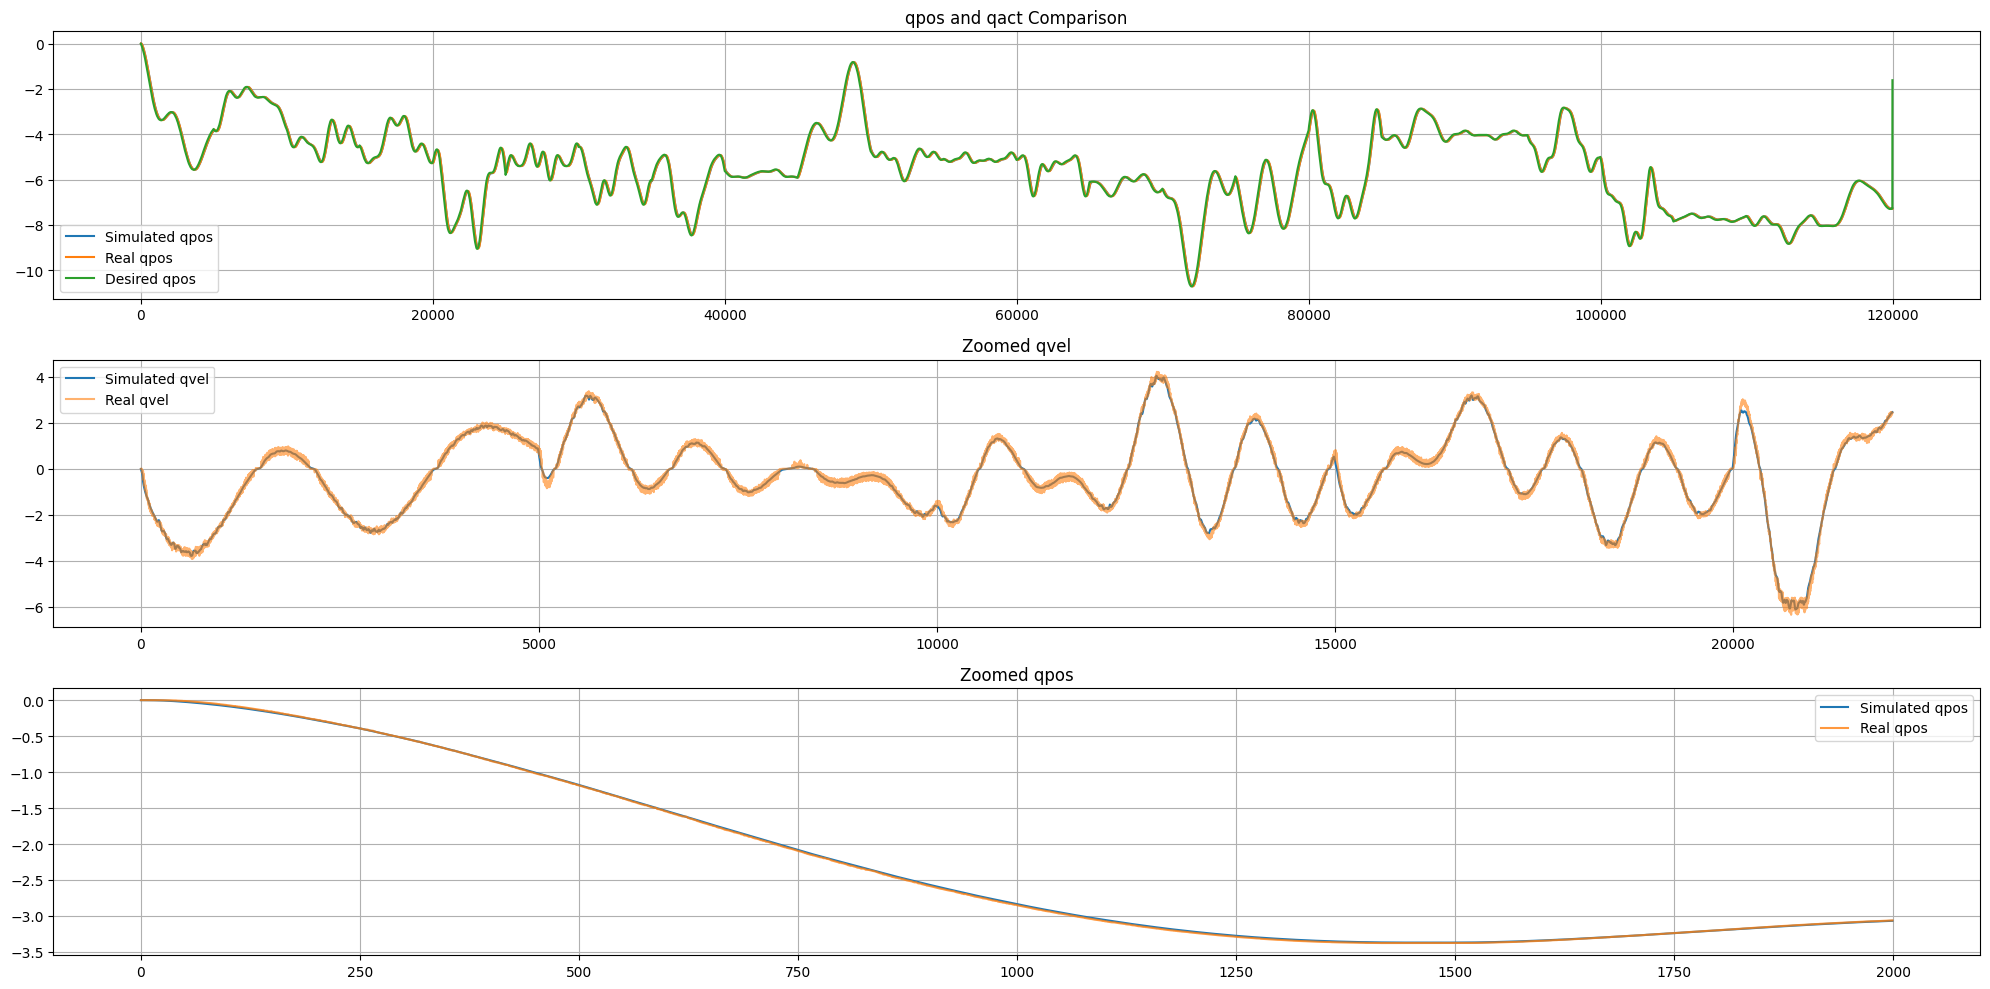

In [11]:
# Create subplots with improved structure
fig, ax = plt.subplots(nrows=3, figsize=(20, 10))

# Plot simulation vs real qpos and qact on the first subplot
ax[0].plot(data_hist["qpos"], label="Simulated qpos")
ax[0].plot(df["qpos"], label="Real qpos")
ax[0].plot(df["qact"], label="Desired qpos")
ax[0].set_title("qpos and qact Comparison")
ax[0].legend()
ax[0].grid(True)

# Plot zoomed qvel for a focused view on the second subplot
ax[1].set_title("Zoomed qvel")
ax[1].plot(data_hist["qvel"][:22000], label="Simulated qvel")
ax[1].plot(df["qvel"][:22000].values, alpha=0.6, label="Real qvel")
ax[1].legend()
ax[1].grid(True)

# Plot zoomed qpos for a focused view on the third subplot, with a step for clarity
ax[2].set_title("Zoomed qpos")
ax[2].plot(data_hist["qpos"][:2000], label="Simulated qpos")
ax[2].plot(df["qpos"][:2000].values, alpha=0.8, label="Real qpos")
ax[2].legend()
ax[2].grid(True)

# Show the plot
plt.tight_layout()  # Ensures everything fits well
plt.show()